# South Australia's country towns: how many buses a week?

- **Towns**: the 52 ABS Urban Centres and Localities (2021) in South Australia outside Greater Adelaide with 1,000 or
  more residents in the 2021 Census (`towns.csv`, with the figures worked out in Plotlay).
- **Trips**: every bus trip in Adelaide Metro's GTFS feed (which carries the state's country coaches and town buses)
  that picks up at a stop inside a town or within 400 m of its edge, on each day of Monday 23 to Sunday 29 November 2026
  (`town_trips.csv`, one row per trip, town and day). A trip's last stop is an arrival, not a pick-up, and is not counted.
- **Kinds**: `regular`, `school` (the route says it is a school service) and `demand responsive`. Only regular trips
  are counted below; the others are counted separately.

From the timetable as published, not what ran on the day. This notebook reads only `../data`.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
DATA = '../data/tables'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
towns = pd.read_csv(f'{DATA}/towns.csv', dtype={'ucl_code': str})
trips = pd.read_csv(f'{DATA}/town_trips.csv', dtype={'ucl_code': str, 'route': str})
print(len(towns), 'towns,', f"{towns.persons_2021.sum():,}", 'residents (2021)')
print(trips.groupby('kind').size())

52 towns, 243,399 residents (2021)
kind
demand responsive       5
regular              2428
school                735
dtype: int64


## 1. Trips in the week and days with a bus, town by town

In [2]:
DAYS = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
reg = trips[trips.kind == 'regular']
by_day = reg.groupby(['ucl_code', 'day']).size().unstack(fill_value=0).reindex(columns=DAYS, fill_value=0)
w = towns[['ucl_code', 'town', 'persons_2021']].set_index('ucl_code').join(by_day).fillna(0)
w[DAYS] = w[DAYS].astype(int)
w['trips_week'] = w[DAYS].sum(axis=1); w['days_served'] = (w[DAYS] > 0).sum(axis=1)
def cls(r):
    if r.trips_week == 0: return 'No scheduled bus'
    if r.days_served <= 4: return 'Some days only'
    return 'Most days' if r.trips_week / r.days_served < 4 else 'Several a day'
w['service'] = w.apply(cls, axis=1)
# the same as the figures worked out in Plotlay
assert (w.trips_week == towns.set_index('ucl_code').trips_week).all() and (w.service == towns.set_index('ucl_code').service).all()
w.sort_values('trips_week').head(16)[['town', 'persons_2021', 'trips_week', 'days_served', 'service'] + DAYS]

,town,persons_2021,trips_week,days_served,service,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
ucl_code,,,,,,,,,,,,
421013,Greenock (L),1042,0,0,No scheduled bus,0,0,0,0,0,0,0
415010,Coober Pedy,1435,0,0,No scheduled bus,0,0,0,0,0,0,0
415012,Freeling,2528,0,0,No scheduled bus,0,0,0,0,0,0,0
415016,Kapunda,2611,0,0,No scheduled bus,0,0,0,0,0,0,0
415039,Roxby Downs,3668,0,0,No scheduled bus,0,0,0,0,0,0,0
415008,Ceduna,2280,2,2,Some days only,0,1,0,0,1,0,0
421034,Quorn (L),1152,2,1,Some days only,0,0,0,0,2,0,0
415003,Balaklava,1966,4,2,Some days only,2,0,0,0,2,0,0
415033,Paringa,1031,4,2,Some days only,0,0,2,0,2,0,0


## 2. Residents by how often the bus comes

                  towns  residents
service                           
No scheduled bus      5      11284
Some days only        7      10096
Most days            19      65821
Several a day        21     156198
A bus on four days or fewer: 12 towns, 21,380 residents (8.8%)


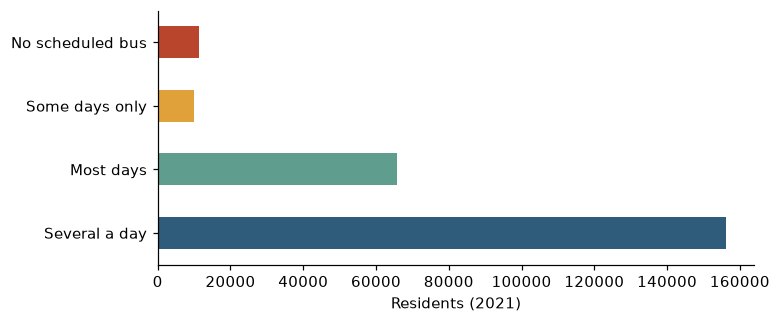

In [3]:
ORDER = ['No scheduled bus', 'Some days only', 'Most days', 'Several a day']
c = w.groupby('service').agg(towns=('town', 'size'), residents=('persons_2021', 'sum')).reindex(ORDER)
print(c)
few = c.loc[ORDER[:2]].sum()
print(f"A bus on four days or fewer: {few.towns} towns, {few.residents:,} residents ({100 * few.residents / c.residents.sum():.1f}%)")
ax = c.residents.plot.barh(color=['#b8452c', '#e0a03a', '#5f9e8f', '#2f5c7a'], figsize=(7, 3))
ax.invert_yaxis(); ax.set_xlabel('Residents (2021)'); ax.set_ylabel('')
plt.show()

## 3. The towns with no scheduled bus: school services only, or nothing in the feed

In [4]:
none = w[w.service == 'No scheduled bus'].index
trips[trips.ucl_code.isin(none)].groupby(['town', 'kind', 'route_name']).size().rename('trips in the week').reset_index()

,town,kind,route_name,trips in the week
0,Freeling,school,Freeling to Evanston via Wasleys,5
1,Freeling,school,Hewett to Nuriootpa via Marananga,10
2,Freeling,school,Kapunda to Evanston via Freeling and Roseworthy,20
3,Greenock (L),school,Tarlee to Nuriootpa via Kapunda and Greenock,10
4,Greenock (L),school,Tarlee to Tanunda via Nuriootpa and Kapunda,10
5,Kapunda,school,Kapunda to Evanston via Freeling and Roseworthy,15
6,Kapunda,school,Kapunda to Hewett Express,5
7,Kapunda,school,Riverton to Nuriootpa via Kapunda,10
8,Kapunda,school,Riverton to Tanunda via Saddleworth and Kapunda,10
9,Kapunda,school,Tarlee to Nuriootpa via Kapunda and Greenock,10


## 4. Trips by day of the week, and a weekday link to Greater Adelaide

Monday       433
Tuesday      414
Wednesday    418
Thursday     433
Friday       461
Saturday     155
Sunday       114
dtype: int64


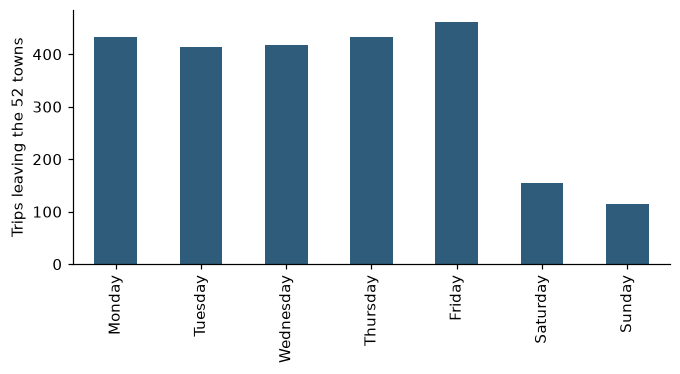

26 of 52 towns have a trip every weekday that goes on to Greater Adelaide


In [5]:
d = w[DAYS].sum()
print(d)
ax = d.plot.bar(color='#2f5c7a', figsize=(7, 3)); ax.set_ylabel('Trips leaving the 52 towns'); ax.set_xlabel('')
plt.show()
ga = reg[reg.goes_on_to_greater_adelaide].groupby(['ucl_code', 'day']).size().unstack(fill_value=0).reindex(columns=DAYS, fill_value=0)
every_weekday = (ga[DAYS[:5]] > 0).all(axis=1)
print(int(every_weekday.sum()), 'of', len(w), 'towns have a trip every weekday that goes on to Greater Adelaide')